# ICT Workers' Individual Issues — Data Visualisation

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr, spearmanr, t as t_dist
from IPython.display import display

os.makedirs("visuals", exist_ok=True)

In [2]:
df = pd.read_csv("ICT_preprocessed.csv")

attributes = ["FC", "JI", "SE", "WS", "WO", "WH", "WE", "TI", "TA"]
FS_columns = [f"{a}_FSMean" for a in attributes]
S_columns = [f"{a}_Smean" for a in attributes]

# Attribute names as defined in ICTInvFldDesc.pdf
ATTR_NAMES = {
    "FC": "Friendship circles", "JI": "Job insecurity", "SE": "Self-efficacy",
    "WS": "Work satisfaction", "WO": "Work overload", "WH": "Work-home conflict",
    "WE": "Work exhaustion", "TI": "Turnover intention", "TA": "Turnaway intention",
}

sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)
print("Number of countries:", df["Country"].nunique())

Dataset shape: (37, 21)
Number of countries: 37


## 1. Distribution of each attribute (FS and S scores)

One histogram per attribute shows the spread and any multi-modality across the 37 countries. Both score sets are shown, FS first and then S, each in its own figure with the same layout. Note that the two sets are on different scales (FS country means are centred near zero, S country means are not), so compare the *shapes* rather than the axis values. Summary statistics for both score sets follow in the tables below.

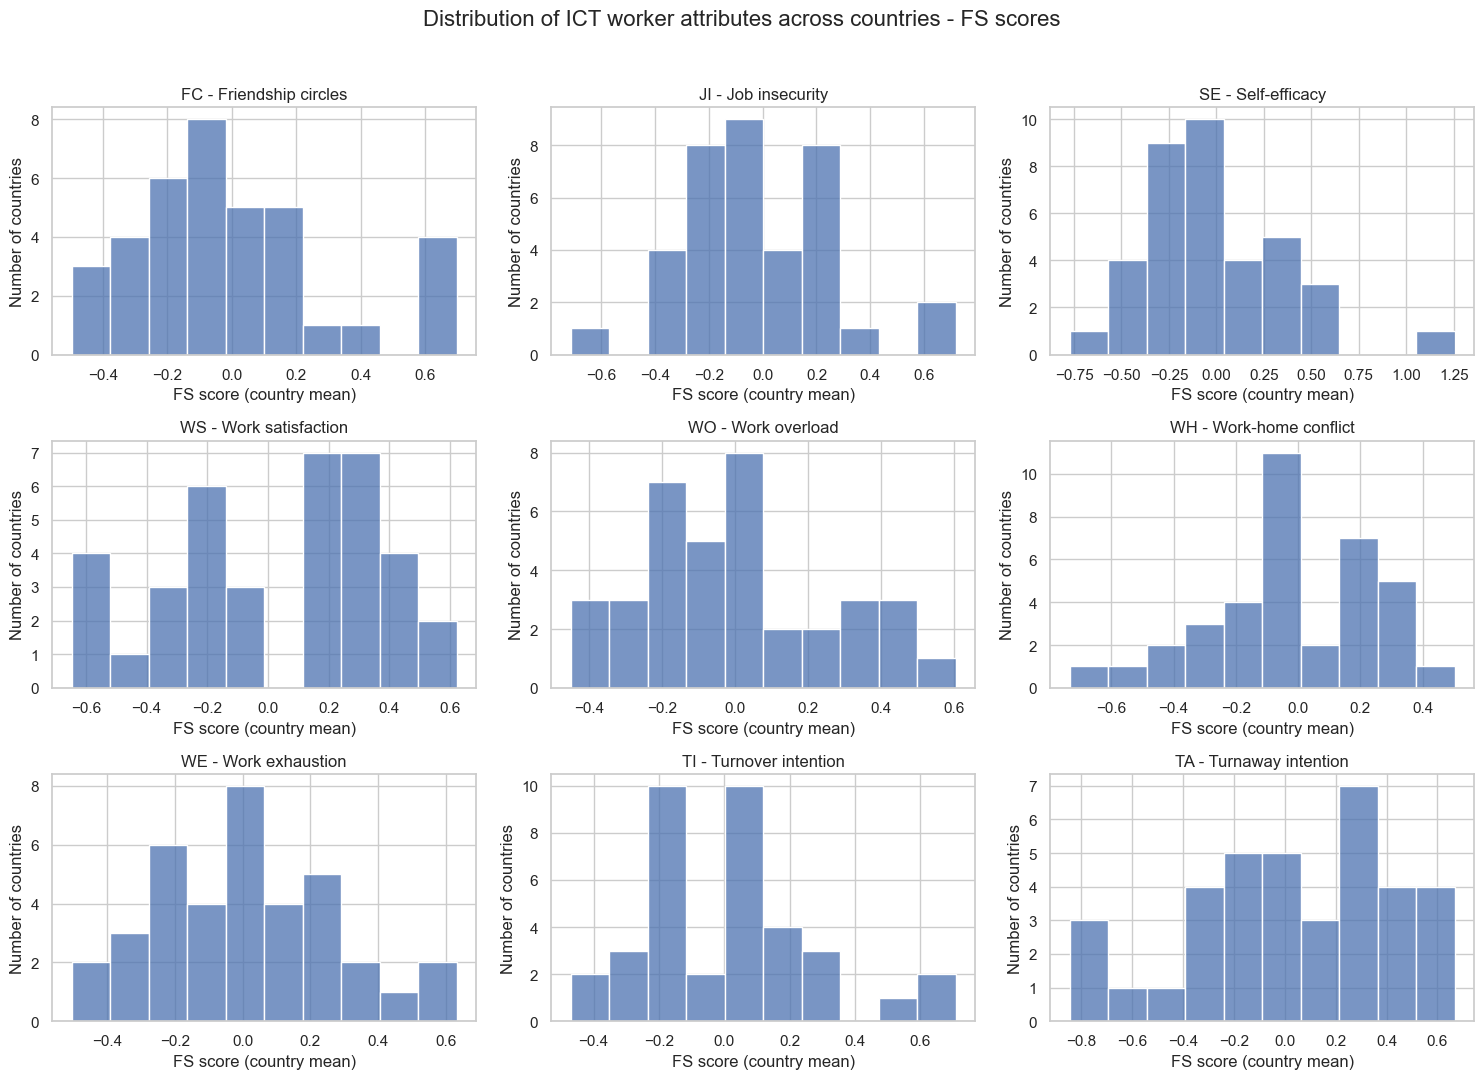

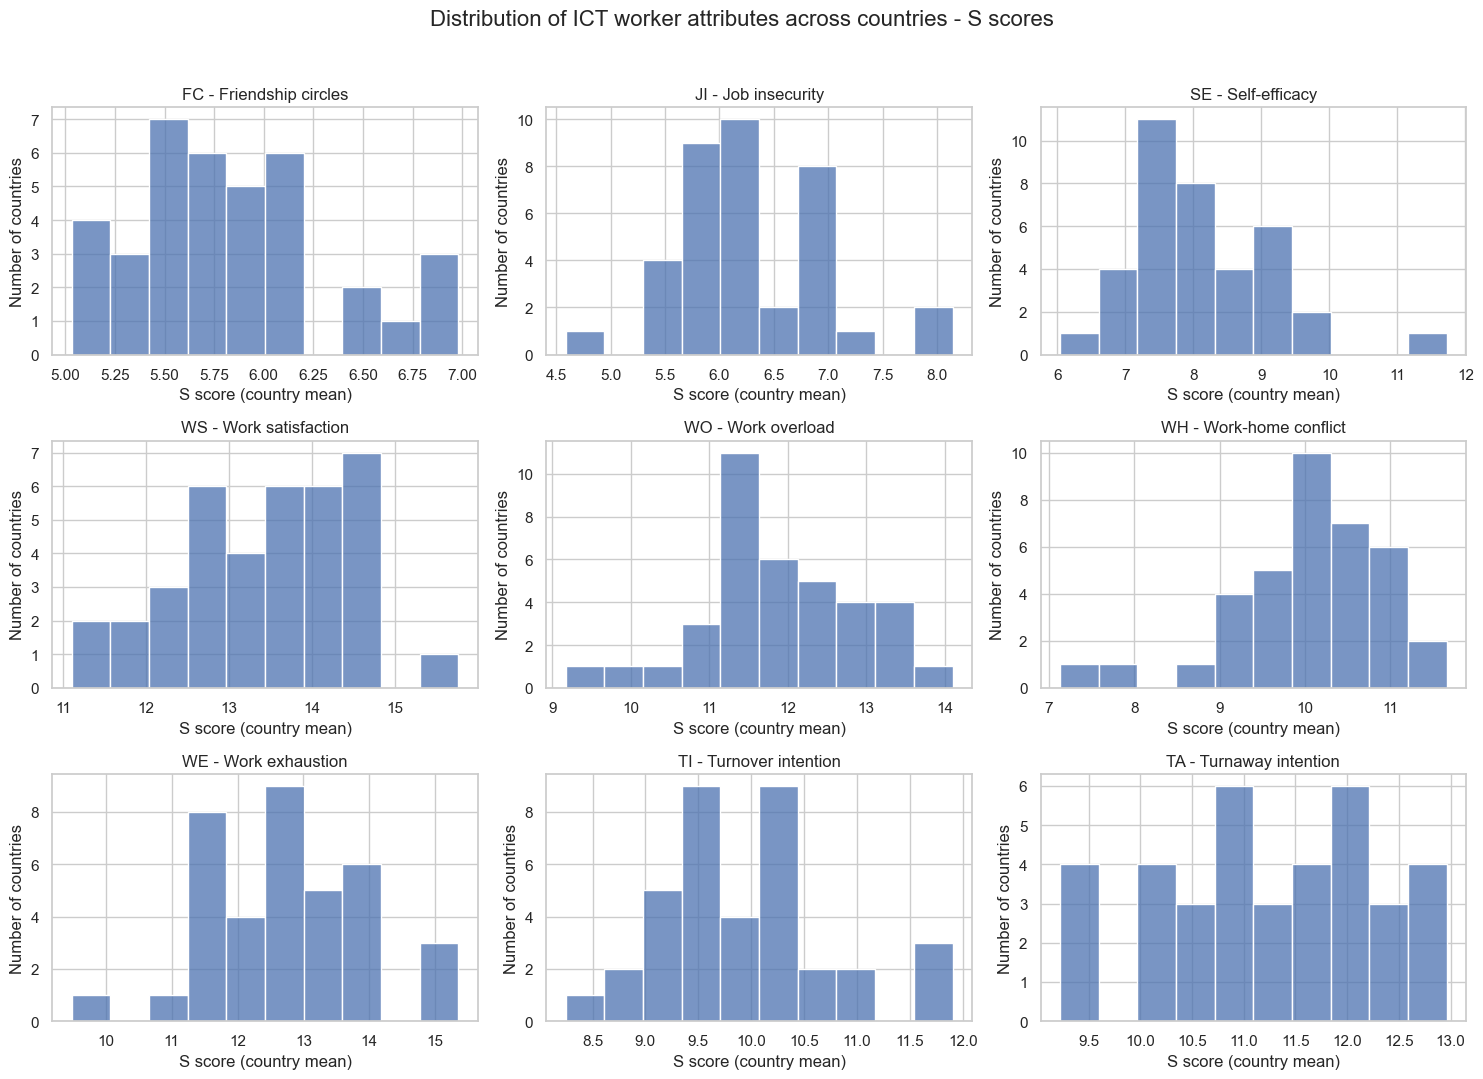

In [3]:
def distribution_figure(columns, label, filename):
    fig, axes = plt.subplots(3, 3, figsize=(15, 11))

    for ax, col, attr in zip(axes.flat, columns, attributes):
        sns.histplot(data=df, x=col, bins=10, kde=False, ax=ax)
        ax.set_title(f"{attr} - {ATTR_NAMES[attr]}")
        ax.set_xlabel(f"{label} score (country mean)")
        ax.set_ylabel("Number of countries")

    fig.suptitle(f"Distribution of ICT worker attributes across countries - {label} scores", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


distribution_figure(FS_columns, "FS", "visuals/FS_distributions.png")
distribution_figure(S_columns, "S", "visuals/S_distributions.png")

In [4]:
FS_summary = df[FS_columns].describe().T
FS_summary.index = attributes

display(FS_summary.round(3))

FS_summary.to_csv("visuals/FS_summary_statistics.csv")

,count,mean,std,min,25%,50%,75%,max
FC,37.0,-0.008,0.309,-0.497,-0.197,-0.041,0.118,0.697
JI,37.0,-0.014,0.275,-0.713,-0.204,-0.046,0.161,0.718
SE,37.0,-0.016,0.379,-0.774,-0.250,-0.106,0.144,1.256
WS,37.0,0.026,0.345,-0.647,-0.257,0.174,0.290,0.623
WO,37.0,-0.004,0.261,-0.450,-0.195,-0.023,0.106,0.604
WH,37.0,-0.014,0.276,-0.735,-0.146,-0.029,0.188,0.503
WE,37.0,-0.000,0.277,-0.506,-0.256,0.006,0.197,0.633
TI,37.0,0.012,0.272,-0.470,-0.185,0.006,0.122,0.709
TA,37.0,0.022,0.412,-0.845,-0.224,0.058,0.294,0.668


In [5]:
S_summary = df[S_columns].describe().T
S_summary.index = attributes

display(S_summary.round(3))

S_summary.to_csv("visuals/S_summary_statistics.csv")

,count,mean,std,min,25%,50%,75%,max
FC,37.0,5.826,0.516,5.032,5.508,5.786,6.064,6.981
JI,37.0,6.292,0.691,4.589,5.838,6.194,6.795,8.140
SE,37.0,8.123,1.076,6.037,7.438,7.842,8.596,11.723
WS,37.0,13.432,1.076,11.108,12.693,13.784,14.261,15.766
WO,37.0,11.902,0.994,9.172,11.311,11.864,12.380,14.100
WH,37.0,10.012,0.922,7.129,9.611,10.011,10.621,11.660
WE,37.0,12.757,1.176,9.484,11.809,12.750,13.585,15.352
TI,37.0,9.965,0.793,8.247,9.415,10.000,10.284,11.903
TA,37.0,11.230,1.060,9.224,10.477,11.221,11.987,12.961


*Not plotted:* mean-score bar charts. The FS means are all close to zero (|mean| ≤ 0.026), so such a chart would only display rounding-level noise, and the S means sit on different scales for different attributes (for example FC about 6 versus WS about 13), so bar heights are not comparable across attributes. The means are in the summary tables above.

## 2. Relationships between attributes

The two correlation matrices are shown side by side with a common colour scale. With only 37 countries, small correlations are not distinguishable from zero (the critical |r| is printed below), and a single extreme country can move a coefficient noticeably.

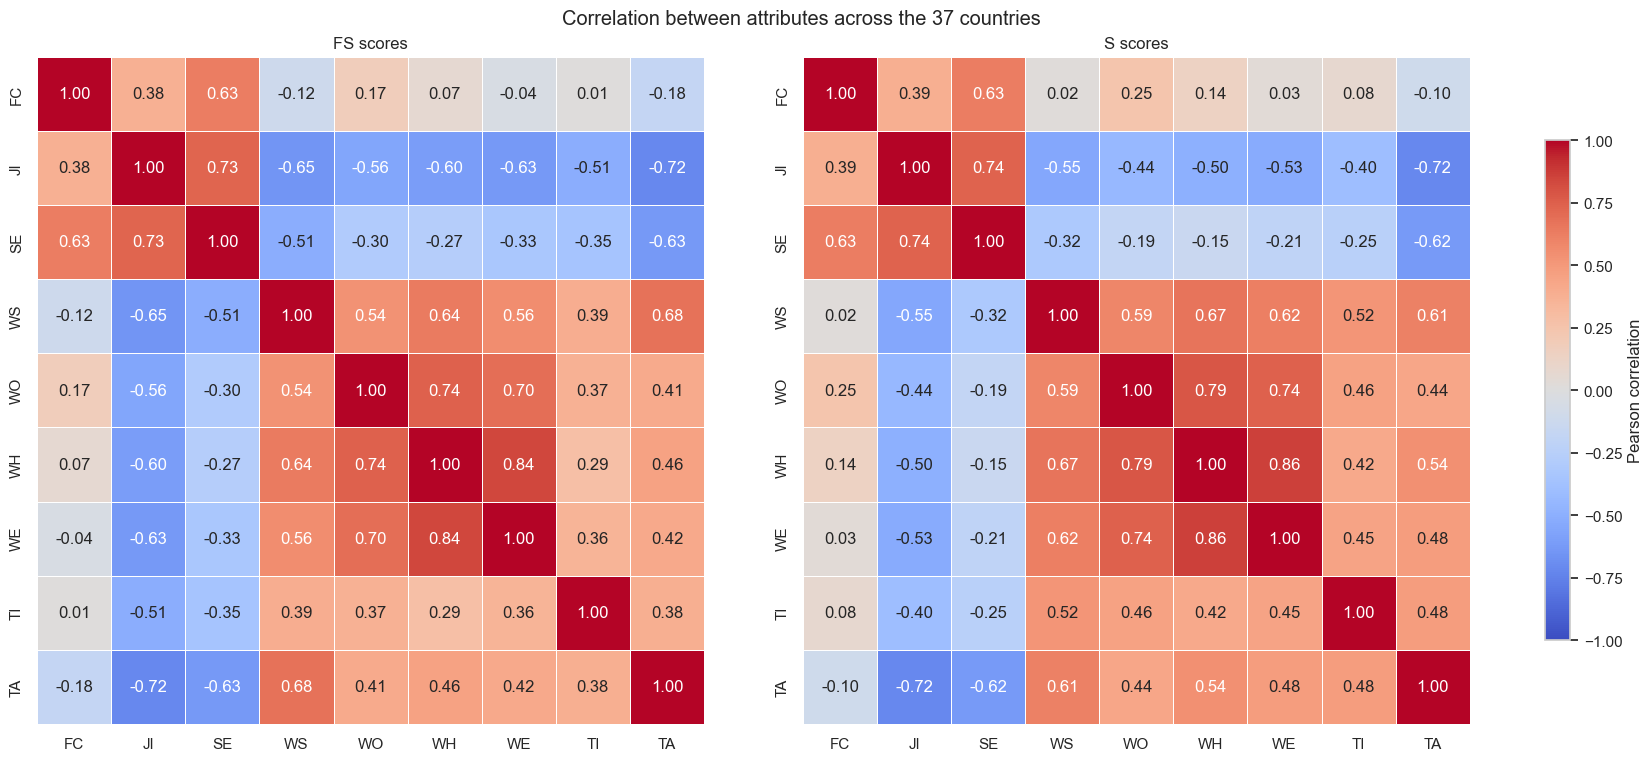

Critical |r| for a two-sided test at the 5% level with n = 37: 0.325
Largest absolute difference between the FS and S correlation matrices: 0.196


In [6]:
FS_data = df[FS_columns].copy()
FS_data.columns = attributes
S_data = df[S_columns].copy()
S_data.columns = attributes

FS_corr = FS_data.corr()
S_corr = S_data.corr()

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), constrained_layout=True)
for ax, corr, title in zip(axes, [FS_corr, S_corr], ["FS scores", "S scores"]):
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
                square=True, linewidths=0.5, cbar=False, ax=ax)
    ax.set_title(title)
fig.colorbar(axes[1].collections[0], ax=axes, shrink=0.75, label="Pearson correlation")
fig.suptitle("Correlation between attributes across the 37 countries")

plt.savefig("visuals/correlation_heatmaps_FS_S.png", dpi=300, bbox_inches="tight")
plt.show()

FS_corr.to_csv("visuals/FS_correlation_matrix.csv")
S_corr.to_csv("visuals/S_correlation_matrix.csv")

n = len(df)
t_crit = t_dist.ppf(0.975, n - 2)
r_crit = t_crit / np.sqrt(t_crit ** 2 + n - 2)
print(f"Critical |r| for a two-sided test at the 5% level with n = {n}: {r_crit:.3f}")
print("Largest absolute difference between the FS and S correlation matrices:",
      round(float(np.abs(FS_corr.values - S_corr.values).max()), 3))

## 3. Country profiles

Each cell is the country's standardised score (z-score across the 37 countries) on one attribute. Rows are ordered by Ward hierarchical clustering of the profiles, so countries with similar profiles sit next to each other and the dendrogram on the left shows how they group. The S scores are the primary score set; the FS version is shown for comparison. The colour scale is symmetric about zero.

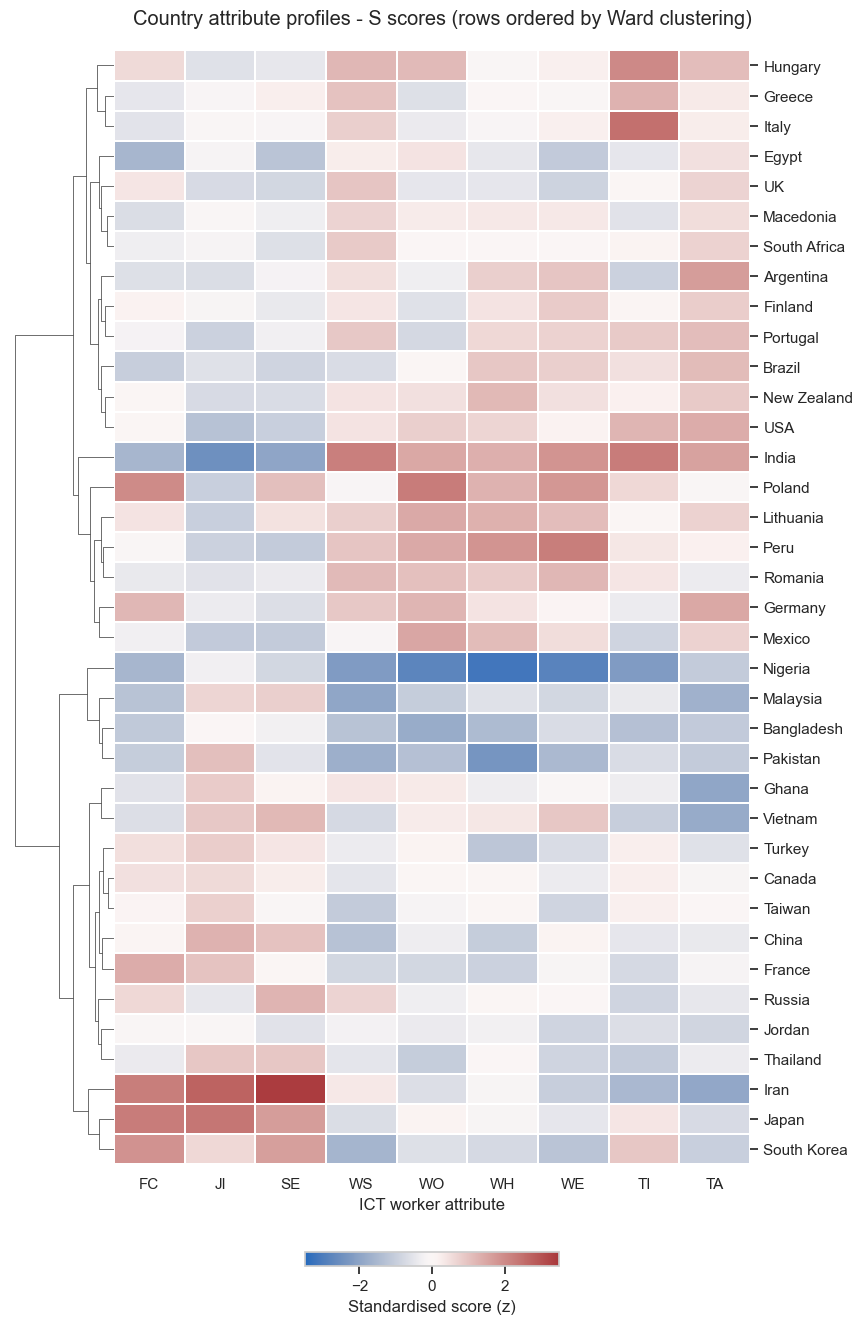

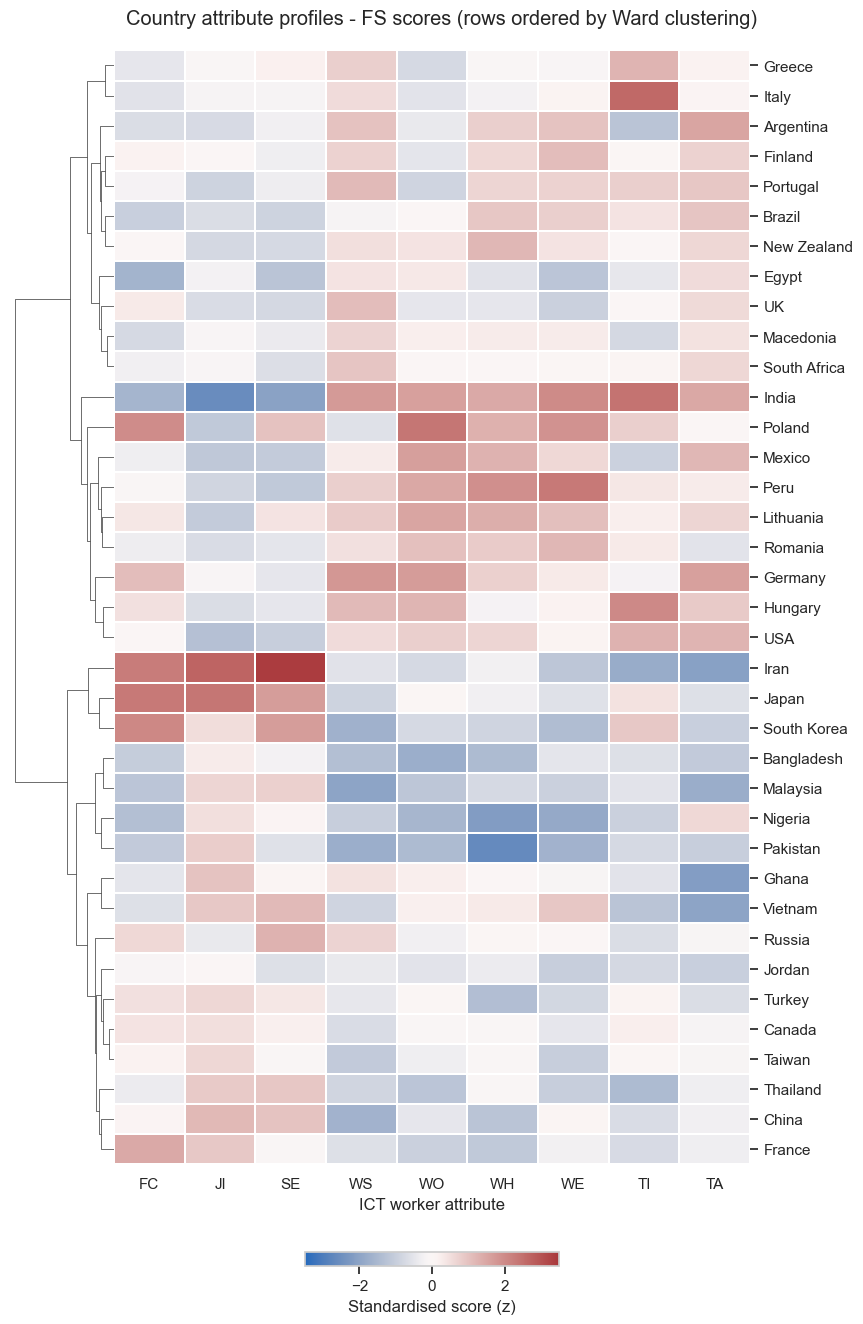

In [7]:
def country_clustermap(columns, title, filename):
    data = pd.DataFrame(
        StandardScaler().fit_transform(df[columns]),
        columns=attributes,
        index=df["Country"]
    )
    lim = float(np.ceil(np.abs(data.values).max() * 2) / 2)   # symmetric colour limits that contain every value

    g = sns.clustermap(
        data, method="ward", metric="euclidean",
        row_cluster=True, col_cluster=False,
        cmap="vlag", center=0, vmin=-lim, vmax=lim, linewidths=0.2,
        figsize=(9, 12), dendrogram_ratio=(0.14, 0.02),
        cbar_pos=None                                   # colour bar is added manually below
    )
    # horizontal colour bar underneath the heatmap (the default position overlaps the dendrogram)
    pos = g.ax_heatmap.get_position()
    cax = g.figure.add_axes([pos.x0 + 0.3 * pos.width, pos.y0 - 0.085, 0.4 * pos.width, 0.012])
    g.figure.colorbar(g.ax_heatmap.collections[0], cax=cax, orientation="horizontal",
                      label="Standardised score (z)")
    g.ax_heatmap.set_xlabel("ICT worker attribute")
    g.ax_heatmap.set_ylabel("")
    plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)
    g.figure.suptitle(title, y=1.0)
    g.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


country_clustermap(S_columns, "Country attribute profiles - S scores (rows ordered by Ward clustering)",
                   "visuals/S_country_heatmap.png")
country_clustermap(FS_columns, "Country attribute profiles - FS scores (rows ordered by Ward clustering)",
                   "visuals/FS_country_heatmap.png")

## 4. Do the two score sets differ?

The brief asks whether grouping on FS and on S scores gives different outcomes. The table reports, for each attribute, how closely the two score sets agree across countries, and which countries are the largest exceptions. The gap is measured as the difference between the country's z-score on the S scale and on the FS scale (positive: the country looks higher on S than on FS).

In [8]:
def standardised_gap(attr):
    fs = df[f"{attr}_FSMean"]
    s = df[f"{attr}_Smean"]
    return (s - s.mean()) / s.std() - (fs - fs.mean()) / fs.std()


comparison_results = []

for attr in attributes:
    fs = df[f"{attr}_FSMean"]
    s = df[f"{attr}_Smean"]
    gap = standardised_gap(attr)
    top = gap.abs().nlargest(2).index

    comparison_results.append({
        "Attribute": attr,
        "Pearson Correlation": pearsonr(fs, s).statistic,
        "Spearman Correlation": spearmanr(fs, s).statistic,
        "Largest gap (S - FS, z units)": f"{df.loc[top[0], 'Country']} ({gap[top[0]]:+.2f})",
        "Second largest gap": f"{df.loc[top[1], 'Country']} ({gap[top[1]]:+.2f})",
    })

FS_S_comparison = pd.DataFrame(comparison_results)

display(FS_S_comparison.round(3))

FS_S_comparison.to_csv(
    "visuals/FS_vs_S_comparison.csv",
    index=False
)

,Attribute,Pearson Correlation,Spearman Correlation,"Largest gap (S - FS, z units)",Second largest gap
0,FC,0.998,0.997,Nigeria (-0.24),South Korea (-0.18)
1,JI,0.986,0.969,Nigeria (-0.78),Bangladesh (-0.28)
2,SE,0.987,0.958,Nigeria (-0.89),Germany (-0.15)
3,WS,0.927,0.926,Nigeria (-1.17),Iran (+0.89)
4,WO,0.972,0.993,Nigeria (-1.21),Germany (-0.45)
5,WH,0.979,0.984,Nigeria (-0.97),Ghana (-0.30)
6,WE,0.981,0.991,Nigeria (-0.96),Germany (-0.24)
7,TI,0.961,0.967,Nigeria (-1.23),Bangladesh (-0.69)
8,TA,0.951,0.940,Nigeria (-1.65),Mexico (-0.46)


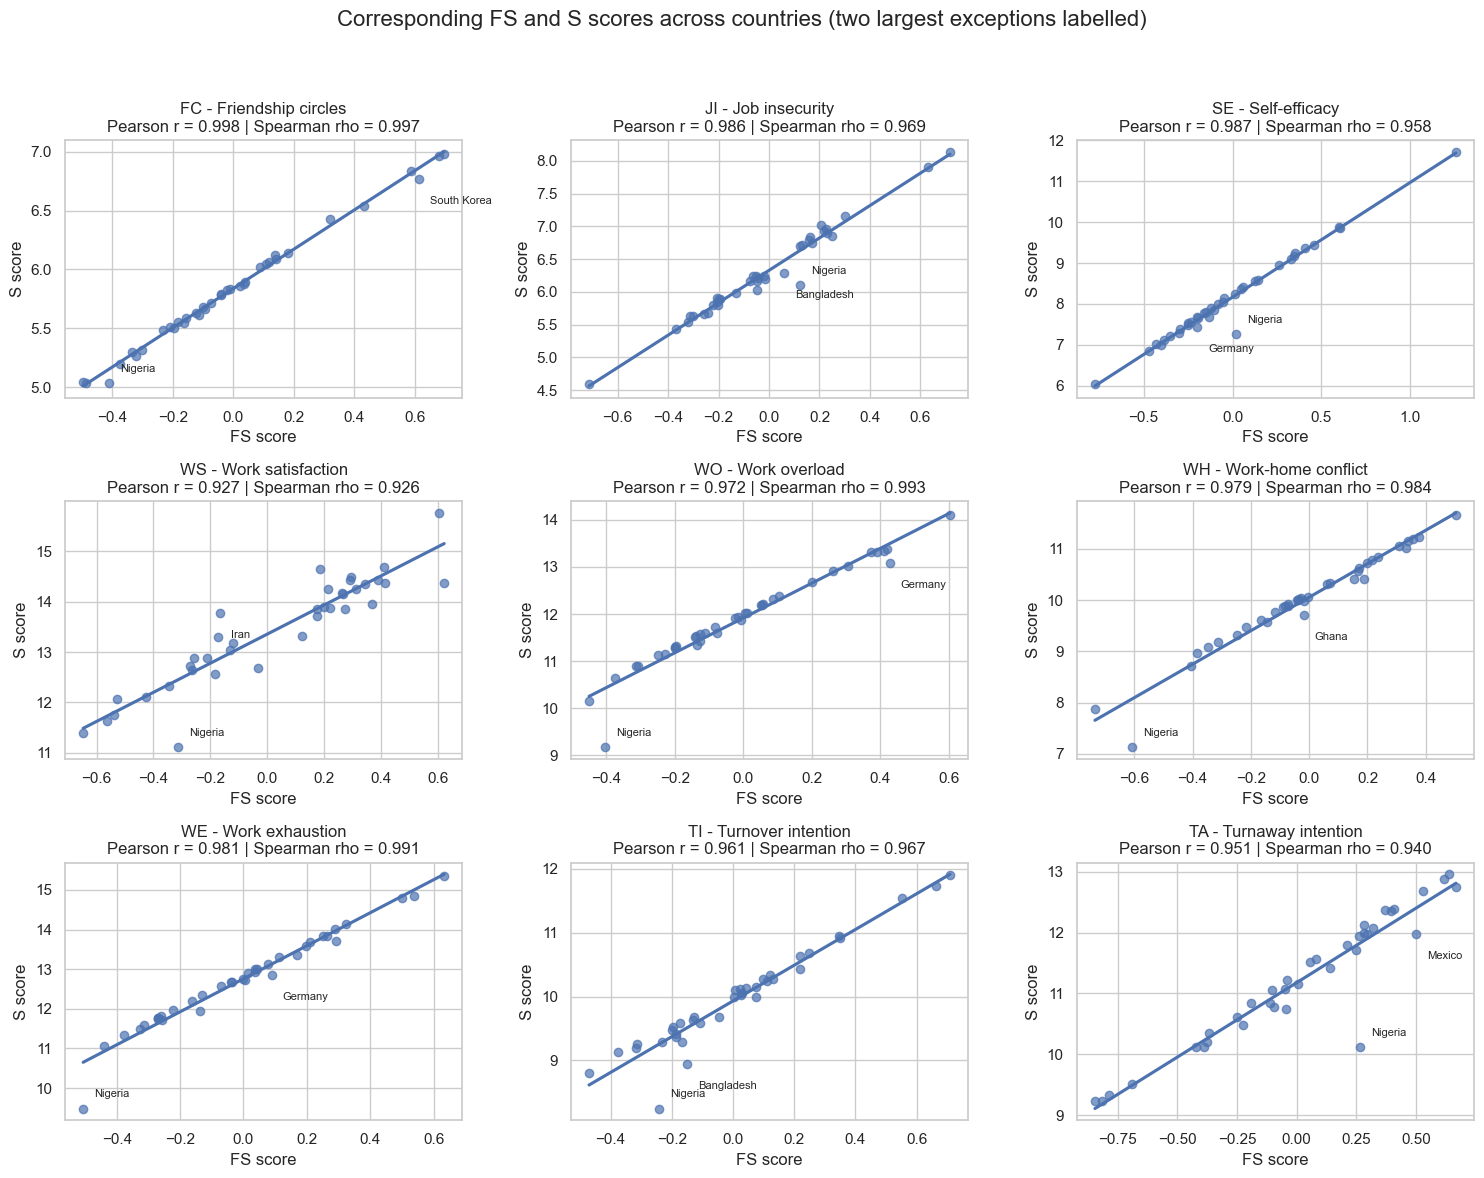

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, attr in zip(axes.flat, attributes):
    x = df[f"{attr}_FSMean"]
    y = df[f"{attr}_Smean"]

    sns.regplot(x=x, y=y, ax=ax, ci=None, scatter_kws={"alpha": 0.7})

    # label the two countries whose FS and S positions disagree most
    gap = standardised_gap(attr)
    for rank, i in enumerate(gap.abs().nlargest(2).index):
        ax.annotate(df.loc[i, "Country"], (x[i], y[i]),
                    xytext=(8, 8 - 26 * rank), textcoords="offset points", fontsize=8)

    r = pearsonr(x, y).statistic
    rho = spearmanr(x, y).statistic

    ax.set_title(f"{attr} - {ATTR_NAMES[attr]}\nPearson r = {r:.3f} | Spearman rho = {rho:.3f}")
    ax.set_xlabel("FS score")
    ax.set_ylabel("S score")

fig.suptitle("Corresponding FS and S scores across countries (two largest exceptions labelled)", fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("visuals/FS_vs_S_scatterplots.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Respondents per country

Each country value is a mean over a different number of respondents (`Num`), so some country scores are more precise than others. Countries below 110 respondents are highlighted; the same threshold is used for the sample-size sensitivity check in the clustering notebook.

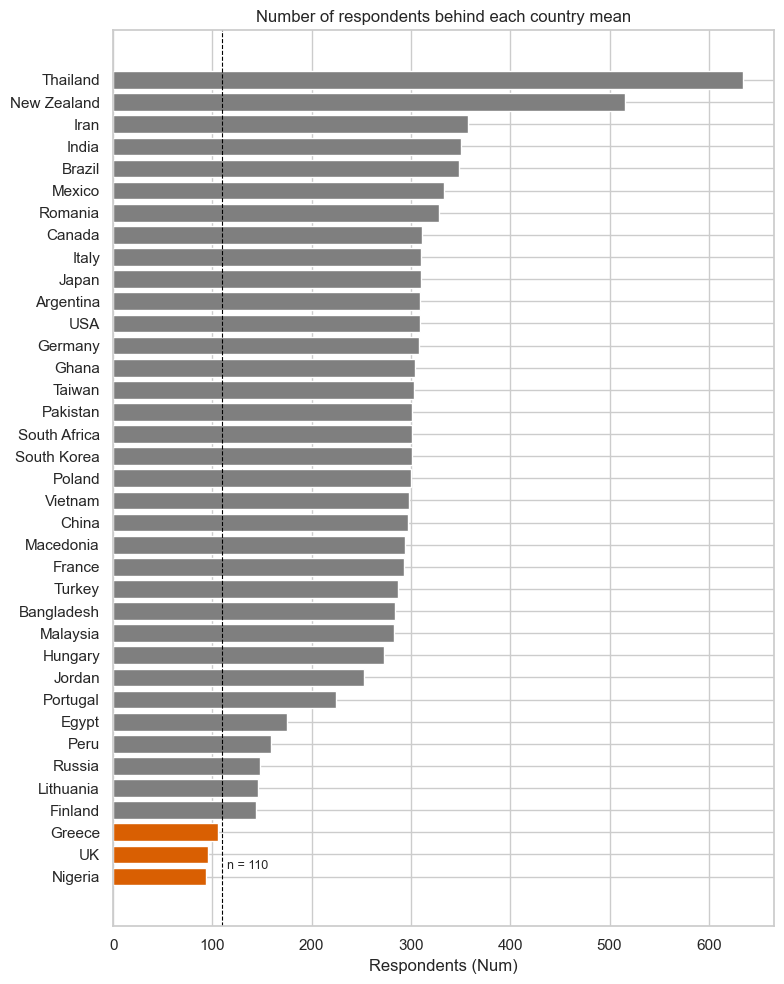

Countries below 110 respondents: Nigeria, UK, Greece


In [10]:
SMALL_N = 110

order = df.sort_values("Num")
colors = np.where(order["Num"] < SMALL_N, "#d95f02", "#7f7f7f")

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(order["Country"], order["Num"], color=colors)
ax.axvline(SMALL_N, color="black", linestyle="--", linewidth=0.8)
ax.text(SMALL_N + 5, 0.2, f"n = {SMALL_N}", fontsize=9, va="bottom")
ax.set_xlabel("Respondents (Num)")
ax.set_title("Number of respondents behind each country mean")

plt.tight_layout()
plt.savefig("visuals/respondents_per_country.png", dpi=300, bbox_inches="tight")
plt.show()

print("Countries below", SMALL_N, "respondents:", ", ".join(order.loc[order["Num"] < SMALL_N, "Country"]))